# Polymarket 5-minute crypto markets: one day in numbers

Polymarket opens a new "Will BTC go up or down in the next 5 minutes?" market every five minutes, around the clock, for six coins, with a 15-minute series alongside. This notebook takes one full UTC day, 2026-10-20: 2,304 markets, recorded next to Binance, Bybit, OKX, Coinbase and the Chainlink oracle that settles them.

**The short version**

- **Polymarket follows Binance in a few hundred milliseconds.** After a sharp Binance move, the BTC Up mid covers half of its response in 350-400 ms. The other coins take 50-250 ms, depending on the coin and the clock. One-second bars hide this completely.
- **Markets settle on a 60-second average, not on the price you are watching.** That rule matches 2,289 of 2,292 outcomes. Reading the direction off Binance gets one market in eight wrong.
- **The price is a fair probability.** On this day, realised frequencies sit on the diagonal at the start, middle and end of a market.
- **Liquidity is thin and costs are high.** The median top of book on BTC is 442 USDC. Taking one share at 50c costs at least 2.25c, of which the fee is 1.75c.

**Data:** the free sample on Hugging Face, downloaded by the first cell: [BTC](https://huggingface.co/datasets/RabbitGo777/polymarket.btc_20261020.v4.1s.parquet), [ETH](https://huggingface.co/datasets/RabbitGo777/polymarket.eth_20261020.v4.1s.parquet), [SOL](https://huggingface.co/datasets/RabbitGo777/polymarket.sol_20261020.v4.1s.parquet), [XRP](https://huggingface.co/datasets/RabbitGo777/polymarket.xrp_20261020.v4.1s.parquet), [DOGE](https://huggingface.co/datasets/RabbitGo777/polymarket.doge_20261020.v4.1s.parquet), [BNB](https://huggingface.co/datasets/RabbitGo777/polymarket.bnb_20261020.v4.1s.parquet). Every number here describes this one day, so treat it as a measurement of 2026-10-20 and not as a law of these markets.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pmlab.data import COINS, ROOT, download_agg, load_exchange, load_oracle, load_polymarket, market_outcomes
from pmlab.plots import BLUE, COIN_COLORS, INK_2, ORANGE, apply_style, save
from pmlab.stats import brier, cluster_bootstrap, taker_fee

apply_style()
pd.set_option("display.max_columns", 30, "display.width", 140)
download_agg()

In [2]:
columns = ["bid_price", "ask_price", "bid_size", "ask_size", "mid_close", "quote_volume"]
pm = pd.concat([load_polymarket(c, tf, columns).assign(tf=tf) for c in COINS for tf in ("5m", "15m")],
               ignore_index=True)
up = pm[pm["outcome"] == "Up"].copy()
up["up_won"] = (up["winning_outcome"].astype(str) == "Up").astype(float).where(up["winning_outcome"].notna())
up["spread_c"] = (up["ask_price"] - up["bid_price"]) * 100
perp = {c: load_exchange(c, columns=("mid_close", "quote_volume"))["mid_close"] for c in COINS}
oracle = {c: load_oracle(c) for c in COINS}
print(f"{len(pm):,} token-seconds, {pm['condition_id'].nunique():,} markets")

2,073,600 token-seconds, 2,304 markets


## 1. The day at a glance

In [3]:
def overview(d):
    m = d.groupby("condition_id", observed=True)["up_won"].first().dropna()
    return pd.Series({"markets": d["condition_id"].nunique(),
                      "volume_usdc": d["quote_volume"].sum(),
                      "median_spread_c": d["spread_c"].median(),
                      "up_won_pct": 100 * m.mean()})

vol = pm.groupby(["coin", "tf"], observed=True)["quote_volume"].sum()
table = up.groupby(["coin", "tf"], observed=True).apply(overview, include_groups=False)
table["volume_usdc"] = vol
table = table.loc[[(c, tf) for c in COINS for tf in ("5m", "15m")]]
table.round({"volume_usdc": 0, "median_spread_c": 2, "up_won_pct": 1}).astype({"markets": int, "volume_usdc": int})

markets  volume_usdc  median_spread_c  up_won_pct
coin tf                                                    
btc  5m       288      6705860              1.0        50.7
     15m       96      1625265              1.0        47.9
eth  5m       288       727638              1.0        51.7
     15m       96       247533              1.0        50.0
sol  5m       288       201505              1.0        51.0
     15m       96        77639              1.0        52.1
xrp  5m       288        83680              2.0        51.0
     15m       96        49401              1.0        52.1
doge 5m       288        56610              2.0        52.1
     15m       96        25648              2.0        52.1
bnb  5m       288        29194              2.0        52.1
     15m       96        31802              2.0        55.2

BTC 5-minute markets carry 86% of the 5-minute volume: 6.7 million USDC out of 7.8 million, counted over live windows only. Up won between 50.7% and 52.1% of each coin's 5-minute markets, which is what a coin flip looks like over 288 trials. The typical spread is one cent on the busiest series and two on the thinnest.

## 2. One market, second by second

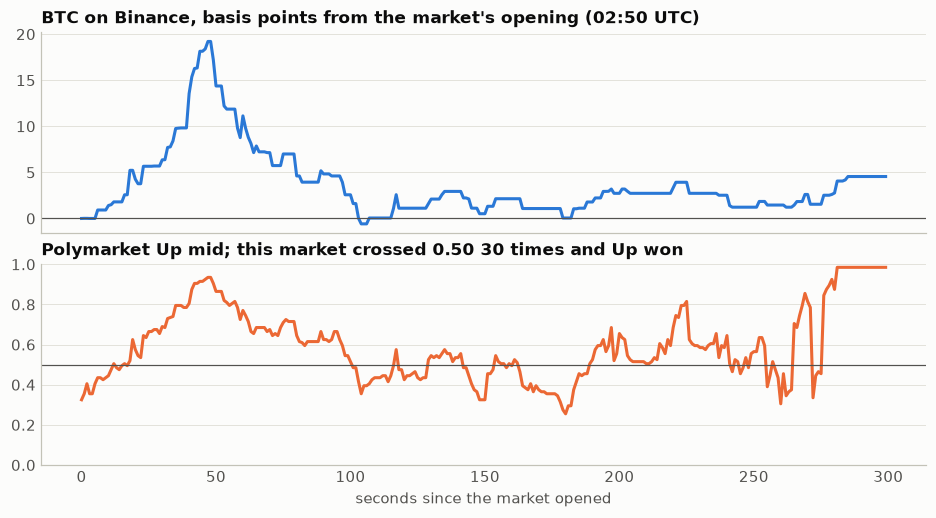

In [4]:
live = up[(up["tf"] == "5m") & (up["coin"] == "btc")]
flips = live.groupby("condition_id", observed=True)["mid_close"].agg(lambda s: int(((s > 0.5) != (s > 0.5).shift()).sum()))
pick = flips.idxmax()
one = live[live["condition_id"] == pick].sort_values("ts")
elapsed = (one["ts"] - one["ts"].iloc[0]).dt.total_seconds()
spot = perp["btc"].reindex(one["ts"]).to_numpy()

fig, (a, b) = plt.subplots(2, 1, figsize=(8.4, 4.6), sharex=True)
a.plot(elapsed, 1e4 * (spot / spot[0] - 1), color=BLUE)
a.axhline(0, color=INK_2, lw=0.8)
a.set_title(f"BTC on Binance, basis points from the market's opening ({one['ts'].iloc[0]:%H:%M} UTC)")
b.plot(elapsed, one["mid_close"], color=ORANGE)
b.axhline(0.5, color=INK_2, lw=0.8)
b.set_ylim(0, 1)
b.set_title(f"Polymarket Up mid; this market crossed 0.50 {flips[pick]} times and {one['winning_outcome'].iloc[0]} won")
b.set_xlabel("seconds since the market opened")
save(fig, "01_one_market")

This is the market with the most reversals of the day. A 19 bp rally carried Up from 0.32 to above 0.90 inside a minute, the move faded, and then the mid swung between about 0.33 and 0.85 in the last 30 seconds while Binance barely moved. Two things stand out. The market opened well away from 0.50 with Binance flat, which the next section explains. And close to the end, moves of only a few basis points swing the price, because by then a few basis points decide the market.

## 3. What actually settles a market

Up wins when Chainlink's 60-second TWAP at the end is at or above the same TWAP at the start. The check below compares
that rule with every recorded outcome, then with two simpler rules that a newcomer might assume: Chainlink's plain price,
and the Binance perpetual mid.

In [5]:
def asof(series, when):
    series = series.dropna()
    series = series[~series.index.duplicated(keep="last")].sort_index()
    return series.reindex(pd.DatetimeIndex(when), method="ffill").to_numpy()

day_end = up["ts"].min().normalize() + pd.Timedelta(days=1)  # the closing TWAP of 24:00 is in the next file
rows = []
for coin in COINS:
    for tf in ("5m", "15m"):
        m = market_outcomes(up[(up["coin"] == coin) & (up["tf"] == tf)])
        m = m[m["end"] < day_end]
        o = oracle[coin].set_index("ts")
        rules = {"twap_60s": o["twap_60s"], "chainlink_price": o["price"], "binance_mid": perp[coin]}
        row = {"coin": coin, "tf": tf, "markets": len(m)}
        for name, series in rules.items():
            row[name] = int(((asof(series, m["end"]) >= asof(series, m["start"])) == (m["up_won"] == 1)).sum())
        rows.append(row)
settle = pd.DataFrame(rows)
total = settle[["markets", "twap_60s", "chainlink_price", "binance_mid"]].sum()
print((total / total["markets"] * 100).round(2).drop("markets").to_string())
settle.set_index(["coin", "tf"])

twap_60s           99.87
chainlink_price    88.22
binance_mid        87.26


markets  twap_60s  chainlink_price  binance_mid
coin tf                                                  
btc  5m       287       287              249          239
     15m       95        95               89           88
eth  5m       287       287              248          247
     15m       95        95               91           90
sol  5m       287       286              251          244
     15m       95        95               88           89
xrp  5m       287       286              249          246
     15m       95        95               87           90
doge 5m       287       287              252          248
     15m       95        94               85           86
bnb  5m       287       287              241          242
     15m       95        95               92           91

In [6]:
opening = up[(up["tf"] == "5m") & (up["ts"] == up["market_start_ts"])].copy()
gaps = []
for coin, d in opening.groupby("coin", observed=True):
    twap = oracle[coin].set_index("ts")["twap_60s"]
    price = oracle[coin].set_index("ts")["price"]
    gap = 1e4 * (asof(price, d["ts"]) / asof(twap, d["ts"]) - 1)
    gaps.append(pd.DataFrame({"coin": coin, "mid": d["mid_close"].to_numpy(), "gap_bps": gap}))
gaps = pd.concat(gaps).dropna()
gaps.groupby("coin").apply(lambda g: pd.Series({"median_abs_opening_distance_from_50c": (g["mid"] - 0.5).abs().median() * 100,
                                                "corr_with_price_minus_twap": g["mid"].corr(g["gap_bps"])}), include_groups=False).loc[list(COINS)].round(2)

,median_abs_opening_distance_from_50c,corr_with_price_minus_twap
coin,,
btc,7.5,0.81
eth,8.0,0.74
sol,8.5,0.81
xrp,8.5,0.84
doge,8.5,0.84
bnb,9.5,0.82


The TWAP rule reproduces 2,289 of 2,292 outcomes. The 12 markets that end at midnight are left out because their closing value sits in the next day's file. The three misses (SOL 5m 03:00, XRP 5m 20:50, DOGE 15m 03:00) fall on oracle gaps, where no value was recorded at the edge of the window.

The plain Chainlink price gets 88% right and the Binance mid 87%, so **about one market in eight resolves against what the exchange chart seems to say**.

The second table shows why markets rarely open at 0.50. The strike is a trailing average, so after a recent move the current price already sits above or below it. The opening mid is typically 7.5 to 9.5 cents from 0.50, and it correlates at 0.74 to 0.85 with Chainlink price minus TWAP at that moment.

## 4. How far does Polymarket lag Binance?

### One-second bars are too coarse

In [7]:
pm5 = up[up["tf"] == "5m"].sort_values("ts")
lags = range(-3, 6)
rows = {}
for coin in COINS:
    d = pm5[pm5["coin"] == coin].set_index("ts")
    change = d.groupby("condition_id", observed=True)["mid_close"].diff()
    ret = np.log(perp[coin]).diff()
    rows[coin] = {lag: change.corr(pd.Series(ret.reindex(d.index - pd.Timedelta(seconds=lag)).to_numpy(), index=d.index))
                  for lag in lags}
pd.DataFrame(rows).rename_axis("Binance leads by (s)").round(3)

,btc,eth,sol,xrp,doge,bnb
Binance leads by (s),,,,,,
-3,0.029,0.015,0.016,0.017,0.023,0.028
-2,0.047,0.033,0.044,0.044,0.045,0.052
-1,0.087,0.085,0.098,0.088,0.093,0.095
0,0.407,0.466,0.450,0.488,0.444,0.480
1,0.151,0.065,0.028,0.021,0.026,0.071
2,0.018,0.011,0.015,0.013,0.010,0.017
3,0.000,0.003,0.007,0.004,0.003,-0.003
4,-0.005,-0.001,0.001,-0.004,-0.002,-0.002
5,-0.001,0.007,0.000,0.003,-0.002,0.005


Almost everything lands in the same one-second bar, with correlation of 0.41 to 0.49 at zero lag. BTC keeps the largest tail at +1 s. A second is simply too long to measure this.

### Tick data: the reaction in milliseconds

`scripts/build_tick_lag.py` reads the raw message capture and rebuilds both prices on a 50 ms grid. An **event** is a
Binance perpetual move in the top 0.05% of all 200 ms moves for that coin. For each event the script follows the Polymarket
Up mid in the direction of the move, keeping events where the mid started between 0.20 and 0.80.

Two clocks are reported. The **receive** clock is when our collector got the message, which is what a trader in that
place would see. The **venue** clock is the timestamp the exchange stamped on it, which removes delivery delay but relies on
Binance and Polymarket clocks agreeing.

The raw day is large, so the results sit in `results/` and this cell only reads them.

In [8]:
summary = pd.read_csv(ROOT / "results" / "tick_lag_summary.csv")
response = pd.read_csv(ROOT / "results" / "tick_lag_response.csv")
xcorr = pd.read_csv(ROOT / "results" / "tick_lag_xcorr.csv")
view = summary.pivot(index="coin", columns="clock", values=["pm_t50_ms", "pm_t90_ms", "xcorr_peak_ms"]).loc[list(COINS)]
view.insert(0, ("events", "receive"), summary[summary["clock"] == "receive"].set_index("coin")["events"])
view.insert(1, ("move_bps", "receive"), summary[summary["clock"] == "receive"].set_index("coin")["binance_move_bps"].round(1))
view.insert(2, ("pm_move_c", "receive"), summary[summary["clock"] == "receive"].set_index("coin")["pm_move_cents"].round(1))
view

events move_bps pm_move_c pm_t50_ms       pm_t90_ms       xcorr_peak_ms      
clock receive  receive   receive   receive venue   receive venue       receive venue
coin                                                                                
btc       100      3.6       9.8       350   400       700   750           200   300
eth        75      5.7       8.4       200   250      1100  1050            50   150
sol       145      4.6       8.2        50   150       150   250            50   150
xrp       113      4.3       7.7        50   100       150   200            50   100
doge      113      4.4      10.4        50   100       150   200            50   100
bnb       114      3.0      11.7        50   100       200   250            50   100

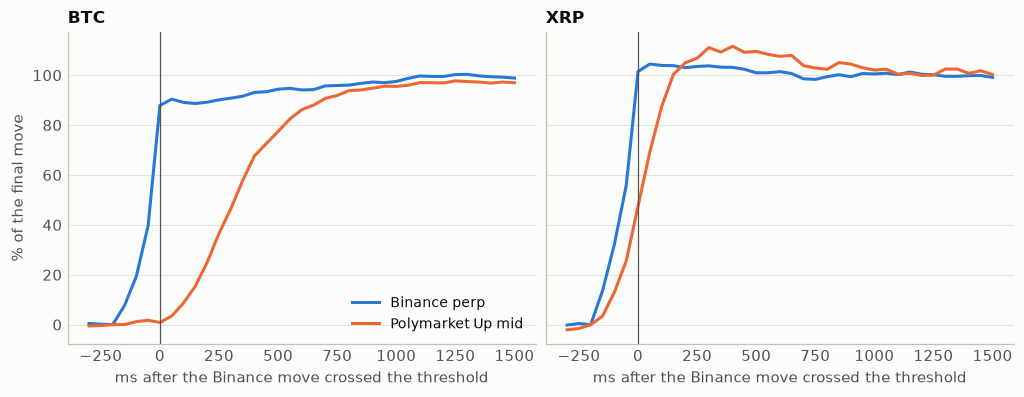

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.5), sharey=True)
for ax, coin in zip(axes, ("btc", "xrp")):
    d = response[(response["coin"] == coin) & (response["clock"] == "receive") & response["ms"].between(-300, 1500)]
    ax.plot(d["ms"], d["binance_pct"], color=BLUE, label="Binance perp")
    ax.plot(d["ms"], d["polymarket_pct"], color=ORANGE, label="Polymarket Up mid")
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.set_title(coin.upper())
    ax.set_xlabel("ms after the Binance move crossed the threshold")
axes[0].set_ylabel("% of the final move")
axes[0].legend(loc="lower right")
save(fig, "02_tick_response")

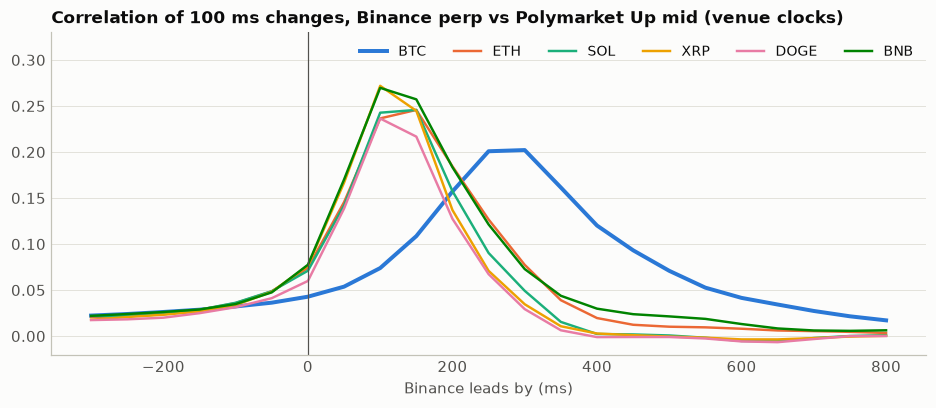

In [10]:
fig, ax = plt.subplots(figsize=(8.4, 3.6))
for coin in COINS:
    d = xcorr[(xcorr["coin"] == coin) & (xcorr["clock"] == "venue") & xcorr["lag_ms"].between(-300, 800)]
    ax.plot(d["lag_ms"], d["correlation"], color=COIN_COLORS[coin], label=coin.upper(), lw=2.6 if coin == "btc" else 1.6)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_title("Correlation of 100 ms changes, Binance perp vs Polymarket Up mid (venue clocks)")
ax.set_xlabel("Binance leads by (ms)")
ax.set_ylim(top=0.33)
ax.legend(ncols=6, loc="upper right")
save(fig, "03_tick_xcorr")

**The lag is real and differs by coin.** Counted from the moment Binance crossed the threshold, by which time Binance itself had done most of its move, the BTC Up mid reached half of its response after 350 ms on the receive clock and 400 ms on venue clocks. It reached 90% after about 700-750 ms. The correlation peak agrees, at 200 and 300 ms.

XRP, DOGE and BNB are much quicker: half the response in 50 ms received, 100 ms on venue clocks. SOL takes 50 and 150 ms. ETH is in between, at 200 and 250 ms, with a long tail to 90% at about 1.1 s.

**Why the clocks differ.** At the median a Binance message reaches the collector about 134 ms after its exchange timestamp, and a Polymarket message about 43 ms after. So on the receive clock the gap looks about 90 ms shorter. Neither figure is the full truth, because the two exchanges' clocks are not proven to agree, so both are shown.

**Why is BTC slowest?** This data does not settle it. Both clocks show it, so it is not a delivery artefact. The BTC book is also by far the busiest, with 103 million price updates against 23 million on XRP, but that is an observation and not a demonstrated cause.

**What this does not show.** A mid that moves 10 cents after a 3.6 bp event is not a 10-cent profit. Makers can pull stale quotes before a taker arrives, top-of-book size is small (section 7), and each coin has only 75 to 145 events on this day. Fills were not simulated.

## 5. Chainlink's delay

In [11]:
rows = []
for coin in COINS:
    o = oracle[coin].set_index("ts")
    grid = o["price"].reindex(pd.date_range(perp[coin].index[0], perp[coin].index[-1], freq="s"))
    filled = np.log(grid.ffill()).diff()
    binance = np.log(perp[coin]).diff().rolling(5).sum()
    chain = filled.rolling(5).sum()
    corr = {lag: binance.shift(lag).corr(chain) for lag in range(-3, 16)}
    rows.append({"coin": coin, "seconds_with_value_pct": 100 * grid.notna().mean(), "median_arrival_lag_ms": o["event_lag_ms"].median(),
                 "binance_lead_s": max(corr, key=corr.get), "peak_corr": max(corr.values())})
pd.DataFrame(rows).set_index("coin").round({"seconds_with_value_pct": 1, "peak_corr": 3})

,seconds_with_value_pct,median_arrival_lag_ms,binance_lead_s,peak_corr
coin,,,,
btc,96.8,1430.0,1,0.902
eth,96.8,1426.0,2,0.914
sol,96.8,1422.0,2,0.909
xrp,96.8,1423.0,2,0.901
doge,96.8,1425.0,2,0.892
bnb,96.8,1423.0,1,0.866


Chainlink published a value in 96.8% of seconds. Each value reached the collector about 1.4 s after its round time, and over 5-second returns Binance leads the oracle by 1-2 s. This matters for any backtest: joining on `ts` alone uses a value before it existed, which is why `pmlab.data.load_oracle` adds an `arrival` column.

## 6. Is the Polymarket price a fair probability?

Prices are compared with outcomes across the six 5-minute series. Rows of one market share one result, and coins move together,
so the intervals resample whole opening times, not rows.

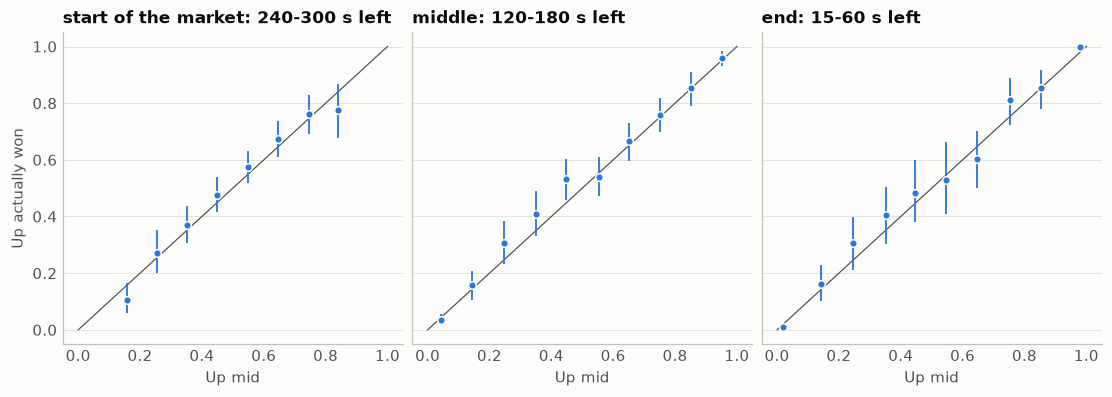

,rows,markets,brier,favourite_won_pct
window,,,,
start of the market: 240-300 s left,20736,1728,0.2194,64.4
middle: 120-180 s left,20736,1728,0.1410,78.5
end: 15-60 s left,15552,1728,0.0282,96.0


In [12]:
sample = up[(up["tf"] == "5m") & up["up_won"].notna() & (up["ts"].dt.second % 5 == 0)].copy()
sample["slot"] = sample["market_start_ts"].astype("int64")
bands = {"start of the market: 240-300 s left": (240, 300), "middle: 120-180 s left": (120, 180), "end: 15-60 s left": (15, 60)}
edges = np.linspace(0, 1, 11)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), sharex=True, sharey=True)
scores = []
for ax, (name, (lo, hi)) in zip(axes, bands.items()):
    d = sample[(sample["tau_sec"] > lo) & (sample["tau_sec"] <= hi)]
    points = []
    for a, b in zip(edges[:-1], edges[1:]):
        x = d[(d["mid_close"] >= a) & (d["mid_close"] < b)]
        if x["slot"].nunique() >= 30:
            points.append((x["mid_close"].mean(), *cluster_bootstrap(x["up_won"].to_numpy(), x["slot"].to_numpy())))
    px, py, low, high = np.array(points).T
    ax.plot([0, 1], [0, 1], color=INK_2, lw=0.8)
    ax.errorbar(px, py, yerr=[py - low, high - py], fmt="o", ms=5, color=BLUE, ecolor=BLUE, elinewidth=1.2, mec="#fcfcfb", mew=1)
    ax.set_title(name)
    ax.set_xlabel("Up mid")
    scores.append({"window": name, "rows": len(d), "markets": d["condition_id"].nunique(), "brier": brier(d["mid_close"], d["up_won"]),
                   "favourite_won_pct": 100 * ((d["mid_close"] > 0.5) == (d["up_won"] == 1)).mean()})
axes[0].set_ylabel("Up actually won")
save(fig, "04_calibration")
pd.DataFrame(scores).set_index("window").round({"brier": 4, "favourite_won_pct": 1})

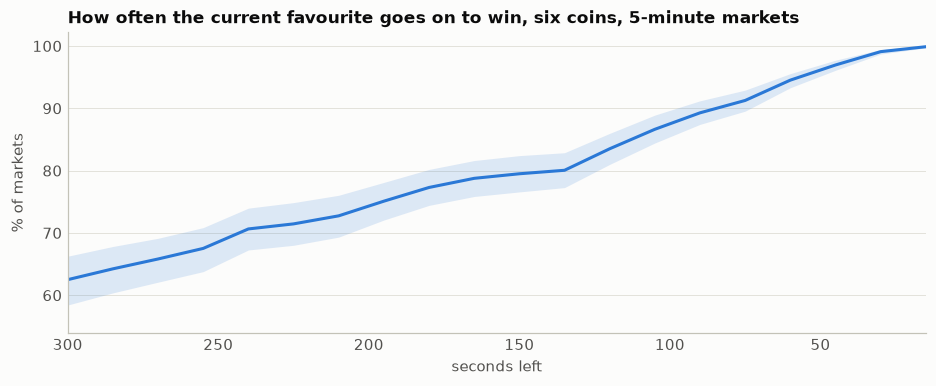

,mean,low,high
left,,,
300.0,62.5,58.4,66.3
240.0,70.6,67.3,74.0
180.0,77.3,74.4,80.2
120.0,83.5,81.0,86.0
60.0,94.5,93.3,95.6
30.0,99.1,98.7,99.4
15.0,99.9,99.7,100.0


In [13]:
sample["fav"] = ((sample["mid_close"] > 0.5) == (sample["up_won"] == 1)).astype(float)
curve = sample.assign(left=(sample["tau_sec"] // 15 + 1) * 15).groupby("left")
points = pd.DataFrame([(left, *cluster_bootstrap(d["fav"].to_numpy(), d["slot"].to_numpy())) for left, d in curve],
                      columns=["left", "mean", "low", "high"]).set_index("left")
fig, ax = plt.subplots(figsize=(8.4, 3.4))
ax.fill_between(points.index, 100 * points["low"], 100 * points["high"], color=BLUE, alpha=0.15, lw=0)
ax.plot(points.index, 100 * points["mean"], color=BLUE)
ax.set_xlim(300, 15)
ax.set_title("How often the current favourite goes on to win, six coins, 5-minute markets")
ax.set_xlabel("seconds left")
ax.set_ylabel("% of markets")
save(fig, "05_favourite")
points.loc[[300, 240, 180, 120, 60, 30, 15]].mul(100).round(1)

Nearly all intervals touch the diagonal, so on this day a price of 0.70 meant roughly a 70% chance at every stage of a market. There is no favourite-longshot bias here that survives the error bars.

The Brier score falls from 0.219 in the first minute to 0.028 between 60 and 15 seconds before the end, as uncertainty resolves. The second chart gives the same story in plain terms: the favourite 300 s before the end wins 62.5% of the time, at 120 s 83.5%, at 60 s 94.5%, and at 30 s 99.1%.

## 7. Liquidity through a market's life

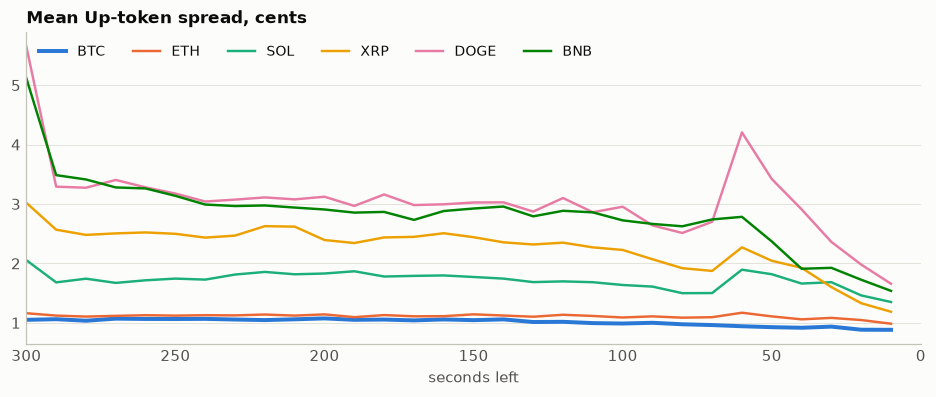

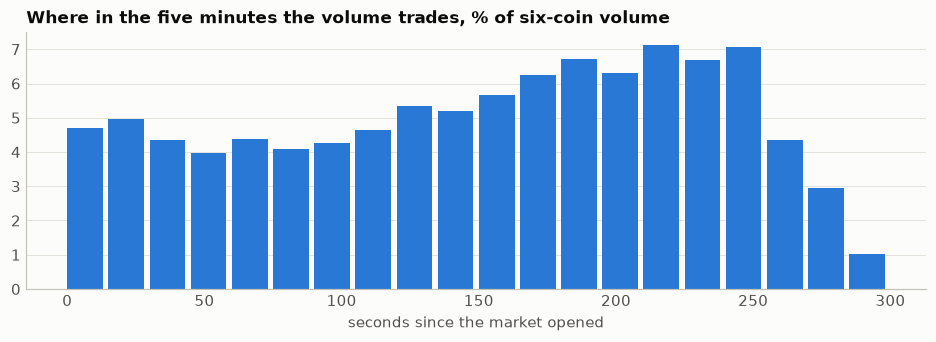

,mean_spread_first_min_c,mean_spread_last_min_c,median_top_of_book_usdc
btc,1.06,0.91,442.0
eth,1.13,1.08,66.0
sol,1.77,1.64,21.0
xrp,2.60,1.73,18.0
doge,3.68,2.76,17.0
bnb,3.62,2.04,15.0


In [14]:
fig, ax = plt.subplots(figsize=(8.4, 3.5))
table = {}
for coin in COINS:
    d = up[(up["coin"] == coin) & (up["tf"] == "5m")]
    s = d.groupby((d["tau_sec"] - 1) // 10 * 10 + 10)["spread_c"].mean()
    ax.plot(s.index, s, color=COIN_COLORS[coin], label=coin.upper(), lw=2.6 if coin == "btc" else 1.6)
    top = d["bid_size"] + d["ask_size"]
    table[coin] = {"mean_spread_first_min_c": d.loc[d["tau_sec"] > 240, "spread_c"].mean(), "mean_spread_last_min_c": d.loc[d["tau_sec"] <= 60, "spread_c"].mean(),
                   "median_top_of_book_usdc": top.median()}
ax.set_xlim(300, 0)
ax.set_title("Mean Up-token spread, cents")
ax.set_xlabel("seconds left")
ax.legend(ncols=6, loc="upper left")
save(fig, "06_spread")

flow = pm[(pm["tf"] == "5m")]
flow = flow.groupby(((300 - flow["tau_sec"]) // 15 * 15).astype(int))["quote_volume"].sum()
fig, ax = plt.subplots(figsize=(8.4, 3))
ax.bar(flow.index, 100 * flow / flow.sum(), width=13, align="edge", color=BLUE)
ax.set_title("Where in the five minutes the volume trades, % of six-coin volume")
ax.set_xlabel("seconds since the market opened")
save(fig, "07_volume_profile")
pd.DataFrame(table).T.round({"mean_spread_first_min_c": 2, "mean_spread_last_min_c": 2, "median_top_of_book_usdc": 0})

BTC and ETH hold a spread near one cent for the whole market. DOGE and BNB start wide at 5 cents, then settle near 3. SOL, XRP and DOGE all jump in the ten seconds after the closing TWAP window opens, 60 seconds before the end, with DOGE going from 2.7 to 4.2 cents. The timing suggests makers widening as settlement starts to be averaged in, though one day cannot prove the reason.

Volume builds to a peak between 210 and 255 seconds, then drops fast. The last 15 seconds carry about 1% of the volume.

Depth is the real limit. The median best bid plus best ask adds up to 442 USDC on BTC, 66 on ETH, and 15 to 21 on the others.

## 8. What it costs to trade

Crossing the book costs half the spread plus a taker fee of `shares × 0.07 × p × (1 − p)`. Makers pay no fee. Buying Up and Down
together at the asks costs more than the dollar they redeem for, and that excess is the overround.

In [15]:
wide = pm[pm["tf"] == "5m"].pivot_table(index=["coin", "condition_id", "ts"], columns="outcome", values="ask_price", observed=True).dropna()
over = ((wide["Up"] + wide["Down"] - 1) * 100).groupby(level="coin", observed=True)
costs = pd.DataFrame({"median_overround_c": over.median(), "share_below_1_usd_pct": over.apply(lambda s: 100 * (s < 0).mean())}).loc[list(COINS)]
at_half = up[(up["tf"] == "5m") & up["mid_close"].between(0.45, 0.55)]
costs["half_spread_at_50c"] = at_half.groupby("coin", observed=True)["spread_c"].median().loc[list(COINS)] / 2
costs["taker_fee_at_50c"] = taker_fee(0.5) * 100
costs["one_way_cost_at_50c"] = costs["half_spread_at_50c"] + costs["taker_fee_at_50c"]
costs.round(2)

,median_overround_c,share_below_1_usd_pct,half_spread_at_50c,taker_fee_at_50c,one_way_cost_at_50c
coin,,,,,
btc,1.0,0.0,0.5,1.75,2.25
eth,1.0,0.0,0.5,1.75,2.25
sol,1.0,0.0,1.0,1.75,2.75
xrp,2.0,0.0,1.0,1.75,2.75
doge,2.0,0.0,1.5,1.75,3.25
bnb,2.0,0.0,1.5,1.75,3.25


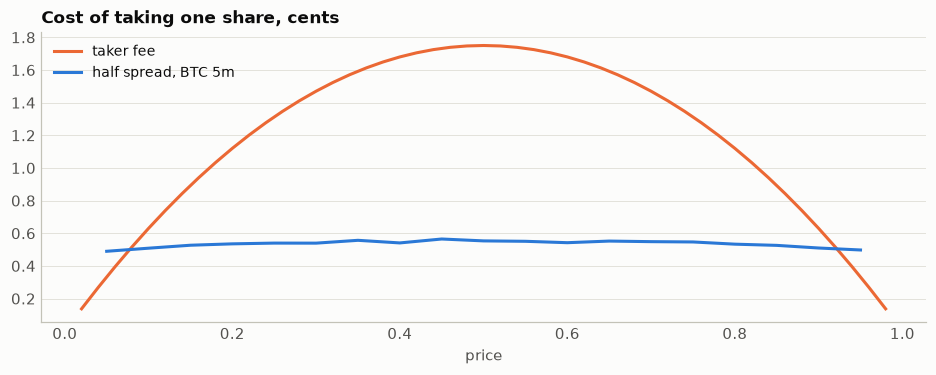

In [16]:
prices = np.linspace(0.02, 0.98, 49)
btc = up[(up["tf"] == "5m") & (up["coin"] == "btc")]
half = btc.groupby((btc["mid_close"] * 20).round() / 20)["spread_c"].mean() / 2
half = half[half.index.to_series().between(0.05, 0.95)]
fig, ax = plt.subplots(figsize=(8.4, 3.3))
ax.plot(prices, taker_fee(prices) * 100, color=ORANGE, label="taker fee")
ax.plot(half.index, half, color=BLUE, label="half spread, BTC 5m")
ax.set_title("Cost of taking one share, cents")
ax.set_xlabel("price")
ax.legend(loc="upper left")
save(fig, "08_cost")

The fee dominates. At a price of 0.50 it is 1.75 cents a share, against a half-spread of 0.5 cents on BTC, for a one-way cost of 2.25 cents. On the thinnest coins it reaches 3.25. On BTC the fee only falls below the half-spread at prices under about 0.08 or over about 0.92. At the one-second closes checked here, Up and Down asks never summed to less than one dollar.

## 9. The day's rhythm

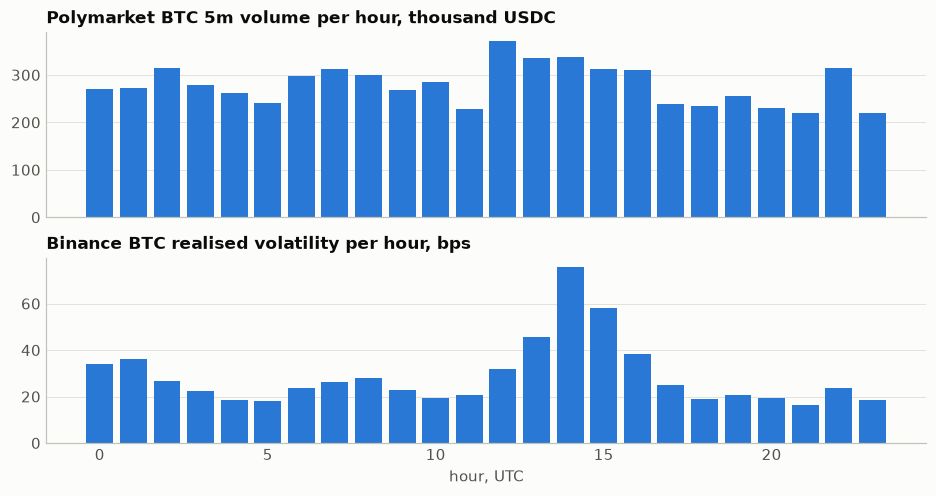

correlation across the 24 hours: 0.62


In [17]:
btc = pm[(pm["coin"] == "btc") & (pm["tf"] == "5m")]
hours = btc.groupby(btc["ts"].dt.hour)["quote_volume"].sum()
squared = np.log(perp["btc"]).diff().pow(2)
realized = squared.groupby(squared.index.hour).sum().pow(0.5) * 1e4
fig, (a, b) = plt.subplots(2, 1, figsize=(8.4, 4.4), sharex=True)
a.bar(hours.index, hours / 1e3, width=0.8, color=BLUE)
a.set_title("Polymarket BTC 5m volume per hour, thousand USDC")
b.bar(realized.index, realized, width=0.8, color=BLUE)
b.set_title("Binance BTC realised volatility per hour, bps")
b.set_xlabel("hour, UTC")
save(fig, "09_intraday")
print("correlation across the 24 hours:", round(np.corrcoef(hours, realized.reindex(hours.index))[0, 1], 2))

BTC volume stays between 220 and 370 thousand USDC an hour, while realised volatility ranges from about 16 to 76 bp with a clear peak at 14:00 UTC. The correlation across the 24 hours is 0.62, so there is a link, but it rests on a single day.

## Where to go next

- **Notebook 02** asks whether a small model can beat these prices.
- **The raw ticks** behind section 4 are on Hugging Face too, for example [BTC](https://huggingface.co/datasets/RabbitGo777/polymarket.btc_20261020.v4.parquet). `scripts/build_tick_lag.py` rebuilds the results.
- **One day is not enough to trust any of this.** The same files for every day from 2026-03-24 are at [keydata.shop](https://keydata.shop), in the same format, so this notebook runs on any of them: put the files in `data/agg`, change `DAY` in `pmlab/data.py` and skip `download_agg()`. The rule holds for this day: 5-minute markets settled on `twap_30s` before 2026-08-14, so section 3 and the oracle feature need that column on earlier days. Shorter samples are at [keydata.shop/samples](https://keydata.shop/samples).